## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()


In [2]:

from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor  
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

## Preprocessing Data and Convert the Datetime

In [3]:
seasonsdata = pd.read_csv('seasonsdata_cleaned.csv')

In [4]:

xx =seasonsdata.drop(["AT_solar_generation_actual"], axis=1)
yy = seasonsdata["AT_solar_generation_actual"]

In [5]:
xx

,datetime,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,cloud_cover_low,...,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation,M,D,H,Y,DOY
0,2015-01-01 00:00:00,-3.3,75,-7.1,-6.8,0.0,0.0,0.0,97,20,...,10.1,1013.2,0,0,0,1,1,0,2015,1
1,2015-01-01 01:00:00,-3.1,78,-6.4,-6.5,0.0,0.0,0.0,99,25,...,10.4,1012.9,0,0,0,1,1,1,2015,1
2,2015-01-01 02:00:00,-2.6,79,-5.7,-6.1,0.0,0.0,0.0,98,35,...,10.8,1012.7,0,0,0,1,1,2,2015,1
3,2015-01-01 03:00:00,-2.2,81,-5.1,-5.7,0.0,0.0,0.0,94,45,...,11.5,1012.7,0,0,0,1,1,3,2015,1
4,2015-01-01 04:00:00,-1.9,84,-4.3,-5.4,0.0,0.0,0.0,96,68,...,14.0,1012.7,0,0,0,1,1,4,2015,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,2020-01-01 19:00:00,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,1,...,13.0,1012.1,0,0,0,1,1,19,2020,1
43796,2020-01-01 20:00:00,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,1,...,13.7,1012.1,0,0,0,1,1,20,2020,1
43797,2020-01-01 21:00:00,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,1,...,13.7,1012.1,0,0,0,1,1,21,2020,1
43798,2020-01-01 22:00:00,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,1,...,12.2,1012.1,0,0,0,1,1,22,2020,1


In [6]:
yy

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
43795    0.0
43796    0.0
43797    0.0
43798    0.0
43799    0.0
Name: AT_solar_generation_actual, Length: 43800, dtype: float64

In [7]:

seasonsdata['datetime'] = pd.to_datetime(seasonsdata['datetime'])

# chronological features
seasonsdata['M'] = seasonsdata['datetime'].dt.month      # month
seasonsdata['D'] = seasonsdata['datetime'].dt.day        # day of month
seasonsdata['H'] = seasonsdata['datetime'].dt.hour       # hour
seasonsdata['Y'] = seasonsdata['datetime'].dt.year       # year
seasonsdata["DOY"] = seasonsdata["datetime"].dt.dayofyear # DAY OF YEAR

period_doy = seasonsdata["DOY"].max()  
seasonsdata["DOY_sin"] = np.sin(2 * np.pi * seasonsdata["DOY"] / period_doy)
seasonsdata["DOY_cos"] = np.cos(2 * np.pi * seasonsdata["DOY"] / period_doy)


#Cyclical encoding for hour (period = 24 hours)
seasonsdata["H_sin"] = np.sin(2 * np.pi * seasonsdata["H"] / 24)
seasonsdata["H_cos"] = np.cos(2 * np.pi * seasonsdata["H"] / 24)

# Cyclical encoding for day of year, Use 365 as period
seasonsdata["DOY_sin"] = np.sin(2 * np.pi * seasonsdata["DOY"] / 365)
seasonsdata["DOY_cos"] = np.cos(2 * np.pi * seasonsdata["DOY"] / 365)

#all conversion used in case needed later with feature selection

In [8]:
seasonsdata

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,...,diffuse_radiation,M,D,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos
0,2015-01-01 00:00:00,0.0,-3.3,75,-7.1,-6.8,0.0,0.0,0.0,97,...,0,1,1,0,2015,1,0.017213,0.999852,0.000000,1.000000
1,2015-01-01 01:00:00,0.0,-3.1,78,-6.4,-6.5,0.0,0.0,0.0,99,...,0,1,1,1,2015,1,0.017213,0.999852,0.258819,0.965926
2,2015-01-01 02:00:00,0.0,-2.6,79,-5.7,-6.1,0.0,0.0,0.0,98,...,0,1,1,2,2015,1,0.017213,0.999852,0.500000,0.866025
3,2015-01-01 03:00:00,0.0,-2.2,81,-5.1,-5.7,0.0,0.0,0.0,94,...,0,1,1,3,2015,1,0.017213,0.999852,0.707107,0.707107
4,2015-01-01 04:00:00,0.0,-1.9,84,-4.3,-5.4,0.0,0.0,0.0,96,...,0,1,1,4,2015,1,0.017213,0.999852,0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,2020-01-01 19:00:00,0.0,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,...,0,1,1,19,2020,1,0.017213,0.999852,-0.965926,0.258819
43796,2020-01-01 20:00:00,0.0,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,...,0,1,1,20,2020,1,0.017213,0.999852,-0.866025,0.500000
43797,2020-01-01 21:00:00,0.0,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,...,0,1,1,21,2020,1,0.017213,0.999852,-0.707107,0.707107
43798,2020-01-01 22:00:00,0.0,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,...,0,1,1,22,2020,1,0.017213,0.999852,-0.500000,0.866025


## Adding Seasons Encoder Instead of Month

In [9]:
#convert the month into seasons

#Season (Se: 1–4)
def get_season(month):
    if month in [3, 4, 5]:
        return 1  # Spring
    elif month in [6, 7, 8]:
        return 2  # Summer
    elif month in [9, 10, 11]:
        return 3  # Fall
    else:  # 12, 1, 2
        return 4  # Winter


seasonsdata['Se'] = seasonsdata['M'].apply(get_season)



In [10]:
# Make sure time is sorted
seasonsdata = seasonsdata.sort_values("datetime").reset_index(drop=True)

target_col = "AT_solar_generation_actual"

# Add lag features (hourly and daily)
seasonsdata["PV_lag1"]  = seasonsdata[target_col].shift(1)
seasonsdata["PV_lag24"] = seasonsdata[target_col].shift(24)

# Drop rows that became NaN due to shifting
seasonsdata = seasonsdata.dropna().copy()


In [11]:
seasonsdata.head(10)

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,...,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos,Se,PV_lag1,PV_lag24
24,2015-01-02 00:00:00,0.0,2.2,86,0.1,-1.4,0.0,0.0,0.0,72,...,0,2015,2,0.034422,0.999407,0.000000,1.000000e+00,4,0.0,0.0
25,2015-01-02 01:00:00,0.0,1.6,87,-0.3,-1.8,0.0,0.0,0.0,83,...,1,2015,2,0.034422,0.999407,0.258819,9.659258e-01,4,0.0,0.0
26,2015-01-02 02:00:00,0.0,0.5,89,-1.1,-3.1,0.0,0.0,0.0,58,...,2,2015,2,0.034422,0.999407,0.500000,8.660254e-01,4,0.0,0.0
27,2015-01-02 03:00:00,0.0,-0.6,89,-2.2,-4.2,0.0,0.0,0.0,82,...,3,2015,2,0.034422,0.999407,0.707107,7.071068e-01,4,0.0,0.0
28,2015-01-02 04:00:00,0.0,-1.3,89,-2.9,-5.1,0.0,0.0,0.0,97,...,4,2015,2,0.034422,0.999407,0.866025,5.000000e-01,4,0.0,0.0
29,2015-01-02 05:00:00,0.0,-3.1,92,-4.2,-6.9,0.0,0.0,0.0,87,...,5,2015,2,0.034422,0.999407,0.965926,2.588190e-01,4,0.0,0.0
30,2015-01-02 06:00:00,0.0,-3.7,93,-4.7,-7.8,0.0,0.0,0.0,99,...,6,2015,2,0.034422,0.999407,1.000000,6.123234e-17,4,0.0,0.0
31,2015-01-02 07:00:00,3.0,-3.5,92,-4.6,-7.8,0.0,0.0,0.0,94,...,7,2015,2,0.034422,0.999407,0.965926,-2.588190e-01,4,0.0,2.0
32,2015-01-02 08:00:00,15.0,-3.1,91,-4.4,-7.4,0.0,0.0,0.0,82,...,8,2015,2,0.034422,0.999407,0.866025,-5.000000e-01,4,3.0,10.0
33,2015-01-02 09:00:00,33.0,-2.3,91,-3.5,-6.7,0.0,0.0,0.0,73,...,9,2015,2,0.034422,0.999407,0.707107,-7.071068e-01,4,15.0,21.0


In [12]:
seasonsdata.Se

24       4
25       4
26       4
27       4
28       4
        ..
43795    4
43796    4
43797    4
43798    4
43799    4
Name: Se, Length: 43776, dtype: int64

In [13]:
seasonsdata['DOY'].value_counts()


DOY
1      120
2      120
3      120
4      120
5      120
      ... 
301    118
152    117
153     99
302     98
366     24
Name: count, Length: 366, dtype: int64

In [14]:
seasonsdata

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,...,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos,Se,PV_lag1,PV_lag24
24,2015-01-02 00:00:00,0.0,2.2,86,0.1,-1.4,0.0,0.0,0.0,72,...,0,2015,2,0.034422,0.999407,0.000000,1.000000,4,0.0,0.0
25,2015-01-02 01:00:00,0.0,1.6,87,-0.3,-1.8,0.0,0.0,0.0,83,...,1,2015,2,0.034422,0.999407,0.258819,0.965926,4,0.0,0.0
26,2015-01-02 02:00:00,0.0,0.5,89,-1.1,-3.1,0.0,0.0,0.0,58,...,2,2015,2,0.034422,0.999407,0.500000,0.866025,4,0.0,0.0
27,2015-01-02 03:00:00,0.0,-0.6,89,-2.2,-4.2,0.0,0.0,0.0,82,...,3,2015,2,0.034422,0.999407,0.707107,0.707107,4,0.0,0.0
28,2015-01-02 04:00:00,0.0,-1.3,89,-2.9,-5.1,0.0,0.0,0.0,97,...,4,2015,2,0.034422,0.999407,0.866025,0.500000,4,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,2020-01-01 19:00:00,0.0,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,...,19,2020,1,0.017213,0.999852,-0.965926,0.258819,4,0.0,0.0
43796,2020-01-01 20:00:00,0.0,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,...,20,2020,1,0.017213,0.999852,-0.866025,0.500000,4,0.0,0.0
43797,2020-01-01 21:00:00,0.0,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,...,21,2020,1,0.017213,0.999852,-0.707107,0.707107,4,0.0,0.0
43798,2020-01-01 22:00:00,0.0,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,...,22,2020,1,0.017213,0.999852,-0.500000,0.866025,4,0.0,0.0


In [15]:
seasonsdata.tail()

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,...,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos,Se,PV_lag1,PV_lag24
43795,2020-01-01 19:00:00,0.0,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,...,19,2020,1,0.017213,0.999852,-0.965926,0.258819,4,0.0,0.0
43796,2020-01-01 20:00:00,0.0,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,...,20,2020,1,0.017213,0.999852,-0.866025,0.500000,4,0.0,0.0
43797,2020-01-01 21:00:00,0.0,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,...,21,2020,1,0.017213,0.999852,-0.707107,0.707107,4,0.0,0.0
43798,2020-01-01 22:00:00,0.0,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,...,22,2020,1,0.017213,0.999852,-0.500000,0.866025,4,0.0,0.0
43799,2020-01-01 23:00:00,0.0,-1.4,87,-3.2,-5.0,0.0,0.0,0.0,0,...,23,2020,1,0.017213,0.999852,-0.258819,0.965926,4,0.0,0.0


In [16]:
xx =seasonsdata.drop(["AT_solar_generation_actual",'datetime'], axis=1)
yy = seasonsdata["AT_solar_generation_actual"]


In [17]:

xx

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,cloud_cover_low,cloud_cover_mid,...,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos,Se,PV_lag1,PV_lag24
24,2.2,86,0.1,-1.4,0.0,0.0,0.0,72,14,11,...,0,2015,2,0.034422,0.999407,0.000000,1.000000,4,0.0,0.0
25,1.6,87,-0.3,-1.8,0.0,0.0,0.0,83,14,10,...,1,2015,2,0.034422,0.999407,0.258819,0.965926,4,0.0,0.0
26,0.5,89,-1.1,-3.1,0.0,0.0,0.0,58,31,25,...,2,2015,2,0.034422,0.999407,0.500000,0.866025,4,0.0,0.0
27,-0.6,89,-2.2,-4.2,0.0,0.0,0.0,82,35,18,...,3,2015,2,0.034422,0.999407,0.707107,0.707107,4,0.0,0.0
28,-1.3,89,-2.9,-5.1,0.0,0.0,0.0,97,22,20,...,4,2015,2,0.034422,0.999407,0.866025,0.500000,4,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,1,0,...,19,2020,1,0.017213,0.999852,-0.965926,0.258819,4,0.0,0.0
43796,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,1,0,...,20,2020,1,0.017213,0.999852,-0.866025,0.500000,4,0.0,0.0
43797,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,1,0,...,21,2020,1,0.017213,0.999852,-0.707107,0.707107,4,0.0,0.0
43798,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,1,0,...,22,2020,1,0.017213,0.999852,-0.500000,0.866025,4,0.0,0.0


In [18]:

yy

24       0.0
25       0.0
26       0.0
27       0.0
28       0.0
        ... 
43795    0.0
43796    0.0
43797    0.0
43798    0.0
43799    0.0
Name: AT_solar_generation_actual, Length: 43776, dtype: float64

## Selecting Features Depends on Chronological and Meteorological

In [90]:
# ALL FEATURE MOGHT BE USED 
#['temperature_2m', 'relative_humidity_2m', 'dew_point_2m',
#       'apparent_temperature', 'precipitation', 'rain', 'snowfall',
#       'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high',
#       'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m',
#       'surface_pressure', 'shortwave_radiation', 'direct_radiation',
#       'diffuse_radiation', 
#        'M', 'D', 'H', 'Y', 'DOY', 'DOY_sin', 'DOY_cos',
#       'H_sin', 'H_cos', 'Se']


# Chronological features
S1 =  ['H', 'Y', 'DOY_sin', 'DOY_cos','H_sin', 'H_cos']   # h and y is very important # m d not much important decreas by max 1 in sme algrahim

# Meteorological features: map these to your actual column names

S2 = ['temperature_2m', # R  temperature_2m decrase by 0.5   apparent_temperature increase by 2
     'relative_humidity_2m', # S  decrase by max 1  # does not make sense with apparent
     'dew_point_2m',
     'apparent_temperature',
     'precipitation', 
    'rain', # W   #  rain increase by 0.5 in some algorathim
     'snowfall',
     'cloud_cover',
     'cloud_cover_low', 
     'cloud_cover_mid',
    'cloud_cover_high',
    'wind_speed_10m', 
     'wind_direction_10m',
     'wind_gusts_10m',
    'surface_pressure',
     'shortwave_radiation', # decrase by 2
     'direct_radiation',
     'diffuse_radiation'
     ]
LAGS = ["PV_lag1", "PV_lag24"] 
S3 = S1 + S2 
S4 = S1 + S2 + LAGS


In [91]:
#now the data is rready to use in the algorathim proccssing 
df=seasonsdata.copy()


In [92]:
df

,datetime,AT_solar_generation_actual,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,...,H,Y,DOY,DOY_sin,DOY_cos,H_sin,H_cos,Se,PV_lag1,PV_lag24
24,2015-01-02 00:00:00,0.0,2.2,86,0.1,-1.4,0.0,0.0,0.0,72,...,0,2015,2,0.034422,0.999407,0.000000,1.000000,4,0.0,0.0
25,2015-01-02 01:00:00,0.0,1.6,87,-0.3,-1.8,0.0,0.0,0.0,83,...,1,2015,2,0.034422,0.999407,0.258819,0.965926,4,0.0,0.0
26,2015-01-02 02:00:00,0.0,0.5,89,-1.1,-3.1,0.0,0.0,0.0,58,...,2,2015,2,0.034422,0.999407,0.500000,0.866025,4,0.0,0.0
27,2015-01-02 03:00:00,0.0,-0.6,89,-2.2,-4.2,0.0,0.0,0.0,82,...,3,2015,2,0.034422,0.999407,0.707107,0.707107,4,0.0,0.0
28,2015-01-02 04:00:00,0.0,-1.3,89,-2.9,-5.1,0.0,0.0,0.0,97,...,4,2015,2,0.034422,0.999407,0.866025,0.500000,4,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,2020-01-01 19:00:00,0.0,0.3,86,-1.8,-3.2,0.0,0.0,0.0,1,...,19,2020,1,0.017213,0.999852,-0.965926,0.258819,4,0.0,0.0
43796,2020-01-01 20:00:00,0.0,0.2,86,-1.9,-3.4,0.0,0.0,0.0,1,...,20,2020,1,0.017213,0.999852,-0.866025,0.500000,4,0.0,0.0
43797,2020-01-01 21:00:00,0.0,-0.5,86,-2.5,-4.1,0.0,0.0,0.0,1,...,21,2020,1,0.017213,0.999852,-0.707107,0.707107,4,0.0,0.0
43798,2020-01-01 22:00:00,0.0,-1.1,87,-3.0,-4.7,0.0,0.0,0.0,1,...,22,2020,1,0.017213,0.999852,-0.500000,0.866025,4,0.0,0.0


## Function of Regression Merics

In [93]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred, rel_tol=0.10, min_target_for_pct=1.0):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)


    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    mask = np.abs(y_true) >= min_target_for_pct
    if mask.sum() > 0:
        yt = y_true[mask]
        yp = y_pred[mask]
        rel_err = np.abs(yt - yp) / np.maximum(np.abs(yt), 1e-6)
        p_factor = np.mean(rel_err <= rel_tol)
    else:
        p_factor = np.nan

    total_abs_err = np.sum(np.abs(y_true - y_pred))
    total_obs = np.sum(np.abs(y_true)) + 1e-6
    q_factor = 1 - (total_abs_err / total_obs)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "p_factor": p_factor,
        "q_factor": q_factor,
    }


# Select S3 for Chronological and Meteorological / S4 fpr PV_lag1+ PV_lag24

In [94]:
xses=seasonsdata[S3]
yses=seasonsdata['AT_solar_generation_actual']
len(yses)==len(xses)


True

In [95]:

xses

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
24,0,2015,0.034422,0.999407,0.000000,1.000000,2.2,86,0.1,-1.4,...,14,11,66,9.7,270,20.2,1011.0,0,0,0
25,1,2015,0.034422,0.999407,0.258819,0.965926,1.6,87,-0.3,-1.8,...,14,10,78,8.4,280,17.6,1010.6,0,0,0
26,2,2015,0.034422,0.999407,0.500000,0.866025,0.5,89,-1.1,-3.1,...,31,25,30,9.4,272,14.8,1010.1,0,0,0
27,3,2015,0.034422,0.999407,0.707107,0.707107,-0.6,89,-2.2,-4.2,...,35,18,79,8.1,249,14.0,1009.7,0,0,0
28,4,2015,0.034422,0.999407,0.866025,0.500000,-1.3,89,-2.9,-5.1,...,22,20,96,8.9,238,14.0,1009.2,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,19,2020,0.017213,0.999852,-0.965926,0.258819,0.3,86,-1.8,-3.2,...,1,0,0,7.8,283,13.0,1012.1,0,0,0
43796,20,2020,0.017213,0.999852,-0.866025,0.500000,0.2,86,-1.9,-3.4,...,1,0,0,8.2,293,13.7,1012.1,0,0,0
43797,21,2020,0.017213,0.999852,-0.707107,0.707107,-0.5,86,-2.5,-4.1,...,1,0,0,7.8,292,13.7,1012.1,0,0,0
43798,22,2020,0.017213,0.999852,-0.500000,0.866025,-1.1,87,-3.0,-4.7,...,1,0,0,7.6,289,12.2,1012.1,0,0,0


In [96]:
yses

24       0.0
25       0.0
26       0.0
27       0.0
28       0.0
        ... 
43795    0.0
43796    0.0
43797    0.0
43798    0.0
43799    0.0
Name: AT_solar_generation_actual, Length: 43776, dtype: float64

## Train Test Split and Scale the whole Data

In [97]:
#split the data
Xses_train, Xses_test, yses_train,yses_test = train_test_split(xses, yses, test_size=0.3, shuffle=False )


In [98]:
Xses_train.tail()

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
30662,14,2018,-0.025818,-0.999667,-0.500000,-8.660254e-01,25.5,32,7.8,26.9,...,0,2,0,2.9,97,19.1,995.4,908,776,132
30663,15,2018,-0.025818,-0.999667,-0.707107,-7.071068e-01,26.6,31,7.9,27.4,...,0,2,0,3.2,63,17.3,995.0,831,688,143
30664,16,2018,-0.025818,-0.999667,-0.866025,-5.000000e-01,27.0,30,7.8,27.5,...,0,5,0,1.5,76,16.9,994.7,745,617,128
30665,17,2018,-0.025818,-0.999667,-0.965926,-2.588190e-01,26.8,30,8.0,26.5,...,0,4,0,0.4,90,14.4,994.6,600,472,128
30666,18,2018,-0.025818,-0.999667,-1.000000,-1.836970e-16,26.6,31,8.0,25.8,...,0,0,0,1.5,315,11.9,994.7,455,354,101


In [99]:
Xses_test

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
30667,19,2018,-0.025818,-0.999667,-0.965926,0.258819,26.1,30,7.0,24.6,...,0,0,0,4.7,9,12.2,994.6,292,210,82
30668,20,2018,-0.025818,-0.999667,-0.866025,0.500000,24.3,34,7.5,22.7,...,0,0,0,6.0,33,13.3,994.5,137,81,56
30669,21,2018,-0.025818,-0.999667,-0.707107,0.707107,22.4,37,7.1,20.5,...,0,0,0,7.7,41,11.5,994.5,26,10,16
30670,22,2018,-0.025818,-0.999667,-0.500000,0.866025,23.0,34,6.2,21.6,...,0,0,0,2.8,230,9.0,995.0,0,0,0
30671,23,2018,-0.025818,-0.999667,-0.258819,0.965926,19.7,48,8.5,18.8,...,0,0,0,3.3,257,5.4,994.8,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,19,2020,0.017213,0.999852,-0.965926,0.258819,0.3,86,-1.8,-3.2,...,1,0,0,7.8,283,13.0,1012.1,0,0,0
43796,20,2020,0.017213,0.999852,-0.866025,0.500000,0.2,86,-1.9,-3.4,...,1,0,0,8.2,293,13.7,1012.1,0,0,0
43797,21,2020,0.017213,0.999852,-0.707107,0.707107,-0.5,86,-2.5,-4.1,...,1,0,0,7.8,292,13.7,1012.1,0,0,0
43798,22,2020,0.017213,0.999852,-0.500000,0.866025,-1.1,87,-3.0,-4.7,...,1,0,0,7.6,289,12.2,1012.1,0,0,0


In [100]:
#scaling the data
scaler = StandardScaler()

# Fit on train 
Xses_train_scaled = scaler.fit_transform(Xses_train)

# Transform TEST 
Xses_test_scaled = scaler.transform(Xses_test)

# to recover the columns names as a dataframe
Xses_train_scaled = pd.DataFrame(Xses_train_scaled, columns=Xses_train.columns, index=Xses_train.index)
Xses_test_scaled  = pd.DataFrame(Xses_test_scaled,  columns=Xses_test.columns,  index=Xses_test.index)


In [101]:
Xses_test_scaled

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
30667,1.083778,1.659508,-0.167093,-1.410922,-1.366178,0.366178,1.636762,-2.472635,0.160314,1.480503,...,-0.738177,-0.898277,-0.917937,-1.154138,-2.331604,-1.064285,-0.138924,0.694173,0.786916,0.333334
30668,1.228252,1.659508,-0.167093,-1.410922,-1.224897,0.707259,1.435913,-2.233571,0.231296,1.301309,...,-0.738177,-0.898277,-0.917937,-0.972682,-2.077207,-0.982615,-0.151503,-0.028002,-0.033526,-0.009748
30669,1.372726,1.659508,-0.167093,-1.410922,-1.000152,1.000152,1.223905,-2.054272,0.174510,1.093823,...,-0.738177,-0.898277,-0.917937,-0.735394,-1.992408,-1.116257,-0.151503,-0.545173,-0.485086,-0.537567
30670,1.517200,1.659508,-0.167093,-1.410922,-0.707259,1.224897,1.290855,-2.233571,0.046742,1.197566,...,-0.738177,-0.898277,-0.917937,-1.419342,0.010968,-1.301870,-0.088610,-0.666312,-0.548686,-0.748694
30671,1.661674,1.659508,-0.167093,-1.410922,-0.366178,1.366178,0.922631,-1.396845,0.373261,0.933492,...,-0.738177,-0.898277,-0.917937,-1.349551,0.297164,-1.569153,-0.113767,-0.666312,-0.548686,-0.748694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,1.083778,3.598954,-0.105691,1.415356,-1.366178,0.366178,-1.242078,0.874267,-1.088976,-1.141378,...,-0.710095,-0.898277,-0.917937,-0.721436,0.572761,-1.004889,2.062323,-0.666312,-0.548686,-0.748694
43796,1.228252,3.598954,-0.105691,1.415356,-1.224897,0.707259,-1.253236,0.874267,-1.103172,-1.160240,...,-0.710095,-0.898277,-0.917937,-0.665604,0.678759,-0.952917,2.062323,-0.666312,-0.548686,-0.748694
43797,1.372726,3.598954,-0.105691,1.415356,-1.000152,1.000152,-1.331344,0.874267,-1.188351,-1.226259,...,-0.710095,-0.898277,-0.917937,-0.721436,0.668160,-0.952917,2.062323,-0.666312,-0.548686,-0.748694
43798,1.517200,3.598954,-0.105691,1.415356,-0.707259,1.224897,-1.398294,0.934033,-1.259333,-1.282846,...,-0.710095,-0.898277,-0.917937,-0.749352,0.636360,-1.064285,2.062323,-0.666312,-0.548686,-0.748694


In [102]:
Xses_test_scaled

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
30667,1.083778,1.659508,-0.167093,-1.410922,-1.366178,0.366178,1.636762,-2.472635,0.160314,1.480503,...,-0.738177,-0.898277,-0.917937,-1.154138,-2.331604,-1.064285,-0.138924,0.694173,0.786916,0.333334
30668,1.228252,1.659508,-0.167093,-1.410922,-1.224897,0.707259,1.435913,-2.233571,0.231296,1.301309,...,-0.738177,-0.898277,-0.917937,-0.972682,-2.077207,-0.982615,-0.151503,-0.028002,-0.033526,-0.009748
30669,1.372726,1.659508,-0.167093,-1.410922,-1.000152,1.000152,1.223905,-2.054272,0.174510,1.093823,...,-0.738177,-0.898277,-0.917937,-0.735394,-1.992408,-1.116257,-0.151503,-0.545173,-0.485086,-0.537567
30670,1.517200,1.659508,-0.167093,-1.410922,-0.707259,1.224897,1.290855,-2.233571,0.046742,1.197566,...,-0.738177,-0.898277,-0.917937,-1.419342,0.010968,-1.301870,-0.088610,-0.666312,-0.548686,-0.748694
30671,1.661674,1.659508,-0.167093,-1.410922,-0.366178,1.366178,0.922631,-1.396845,0.373261,0.933492,...,-0.738177,-0.898277,-0.917937,-1.349551,0.297164,-1.569153,-0.113767,-0.666312,-0.548686,-0.748694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43795,1.083778,3.598954,-0.105691,1.415356,-1.366178,0.366178,-1.242078,0.874267,-1.088976,-1.141378,...,-0.710095,-0.898277,-0.917937,-0.721436,0.572761,-1.004889,2.062323,-0.666312,-0.548686,-0.748694
43796,1.228252,3.598954,-0.105691,1.415356,-1.224897,0.707259,-1.253236,0.874267,-1.103172,-1.160240,...,-0.710095,-0.898277,-0.917937,-0.665604,0.678759,-0.952917,2.062323,-0.666312,-0.548686,-0.748694
43797,1.372726,3.598954,-0.105691,1.415356,-1.000152,1.000152,-1.331344,0.874267,-1.188351,-1.226259,...,-0.710095,-0.898277,-0.917937,-0.721436,0.668160,-0.952917,2.062323,-0.666312,-0.548686,-0.748694
43798,1.517200,3.598954,-0.105691,1.415356,-0.707259,1.224897,-1.398294,0.934033,-1.259333,-1.282846,...,-0.710095,-0.898277,-0.917937,-0.749352,0.636360,-1.064285,2.062323,-0.666312,-0.548686,-0.748694


In [103]:
Xses_train_scaled

,H,Y,DOY_sin,DOY_cos,H_sin,H_cos,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,shortwave_radiation,direct_radiation,diffuse_radiation
24,-1.661226,-1.249662,-0.081136,1.414728,-0.000152,1.414366,-1.030070,0.874267,-0.819243,-0.971616,...,-0.345029,-0.603832,0.695199,-0.456232,0.434962,-0.470323,1.923958,-0.666312,-0.548686,-0.748694
25,-1.516752,-1.249662,-0.081136,1.414728,0.365873,1.366178,-1.097020,0.934033,-0.876029,-1.009340,...,-0.345029,-0.630599,0.988496,-0.637688,0.540961,-0.663360,1.873644,-0.666312,-0.548686,-0.748694
26,-1.372278,-1.249662,-0.081136,1.414728,0.706955,1.224897,-1.219761,1.053565,-0.989600,-1.131946,...,0.132365,-0.229082,-0.184694,-0.498106,0.456162,-0.871247,1.810751,-0.666312,-0.548686,-0.748694
27,-1.227804,-1.249662,-0.081136,1.414728,0.999848,1.000152,-1.342503,1.053565,-1.145761,-1.235690,...,0.244693,-0.416457,1.012938,-0.679562,0.212365,-0.930643,1.760437,-0.666312,-0.548686,-0.748694
28,-1.083331,-1.249662,-0.081136,1.414728,1.224593,0.707259,-1.420611,1.053565,-1.245137,-1.320571,...,-0.120373,-0.362921,1.428443,-0.567897,0.095767,-0.930643,1.697545,-0.666312,-0.548686,-0.748694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30662,0.361409,1.659508,-0.167093,-1.410922,-0.707259,-1.224593,1.569812,-2.353103,0.273885,1.697421,...,-0.738177,-0.844742,-0.917937,-1.405384,-1.398815,-0.551992,-0.038296,3.564239,4.386681,0.993107
30663,0.505883,1.659508,-0.167093,-1.410922,-1.000152,-0.999848,1.692553,-2.412869,0.288082,1.744577,...,-0.738177,-0.844742,-0.917937,-1.363509,-1.759211,-0.685634,-0.088610,3.205480,3.827000,1.138257
30664,0.650357,1.659508,-0.167093,-1.410922,-1.224897,-0.706955,1.737187,-2.472635,0.273885,1.754008,...,-0.738177,-0.764438,-0.917937,-1.600797,-1.621412,-0.715332,-0.126345,2.804790,3.375439,0.940325
30665,0.794831,1.659508,-0.167093,-1.410922,-1.366178,-0.365873,1.714870,-2.472635,0.302278,1.659696,...,-0.738177,-0.791206,-0.917937,-1.754336,-1.473014,-0.900945,-0.138924,2.129206,2.453238,0.940325


In [104]:
#we are using time series cross validation
tscv = TimeSeriesSplit(n_splits=5)


## RandomSearch with Random Forest Regressor 

In [105]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_dist_rf = {
    'n_estimators': [200, 300, 700, 1000],  # More trees often help
    'max_depth': [7, 12, 18, 20, None],  # Try deeper trees
    'min_samples_split': [2, 5, 10],  # Lower values = more splits
    'min_samples_leaf': [1, 4 , 6],  # Lower values = finer granularity
    'max_features': ['sqrt', 'log2', 0.5, 0.9],  # More feature options
    'bootstrap': [True],
    'max_samples': [0.7, 0.8, 1.0]  # Include full sample option
}

rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_random_model = RandomizedSearchCV(
    estimator=rf_reg,
    param_distributions=param_dist_rf,
    n_iter=30,  # More iterations for better search
    cv=tscv,
    scoring='r2',  # Changed from RMSE to R²
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=True
)


rf_random_model.fit(Xses_train_scaled, yses_train)

print("Best RF Parameters:", rf_random_model.best_params_)
print("Best RF CV RMSE:", -rf_random_model.best_score_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best RF Parameters: {'n_estimators': 700, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_samples': 1.0, 'max_features': 0.5, 'max_depth': 20, 'bootstrap': True}
Best RF CV RMSE: -0.9311823217136681


In [106]:
#Evaluate Best Random Forest Regressor
best_rf_random = rf_random_model.best_estimator_
y_pred_rfr = best_rf_random.predict(Xses_test_scaled)
metrics_rf_random = regression_metrics(yses_test, y_pred_rfr)

In [107]:
metrics_rf_random

{'MAE': 25.87489345268776,
 'MSE': 2501.6935195116466,
 'RMSE': np.float64(50.01693232807912),
 'R2': 0.9498845712279237,
 'p_factor': np.float64(0.3105229180116204),
 'q_factor': np.float64(0.8322258444183087)}

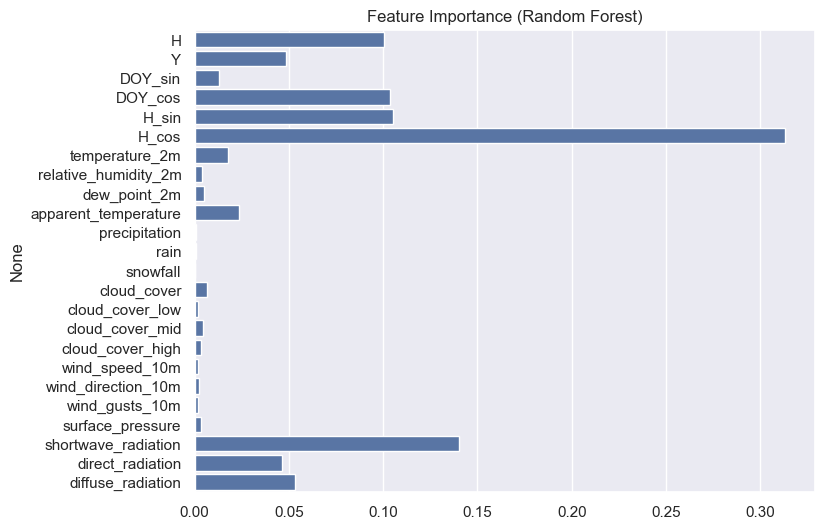

In [108]:
importances = best_rf_random.feature_importances_
feat_names = Xses_train.columns

plt.figure(figsize=(8,6))
sns.barplot(x=importances, y=feat_names)
plt.title("Feature Importance (Random Forest)")
plt.savefig("Feature Importance (Random Forest).png", dpi=1000, bbox_inches="tight")

plt.show()




## RandomSearch with XGBoost

In [109]:
xgb = XGBRegressor(
    objective='reg:squarederror',
    device="cpu",
    random_state=42,
    tree_method='hist'
)

param_dist_xgb = {
    'n_estimators': [500, 800, 1000],
    'max_depth': [3,5,9,12],
    'learning_rate': [0.05,0.01, 0.15],
    'subsample': [0.5,0.7, 0.9],
    'colsample_bytree': [0.4,0.7, 0.9]
}

xgb_search_model = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist_xgb,
    n_iter=15,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_search_model.fit(Xses_train_scaled, yses_train)
best_xgb_search_params = xgb_search_model.best_params_
print("Best XGB params:", best_xgb_search_params)


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGB params: {'subsample': 0.7, 'n_estimators': 1000, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


In [110]:
# ----- XGBoost -----
xgb_search_model = XGBRegressor(
        objective='reg:squarederror',
        random_state=42,
        tree_method='hist',
        **best_xgb_search_params
)
xgb_search_model.fit(Xses_train_scaled, yses_train)
y_pred_xgb_search = xgb_search_model.predict(Xses_test_scaled)
metrics_xgb_search = regression_metrics(yses_test, y_pred_xgb_search)

In [111]:
metrics_xgb_search

{'MAE': 26.823151138717225,
 'MSE': 2464.5237084830906,
 'RMSE': np.float64(49.64396950771655),
 'R2': 0.9506291792314799,
 'p_factor': np.float64(0.3262750161394448),
 'q_factor': np.float64(0.8260772922382449)}

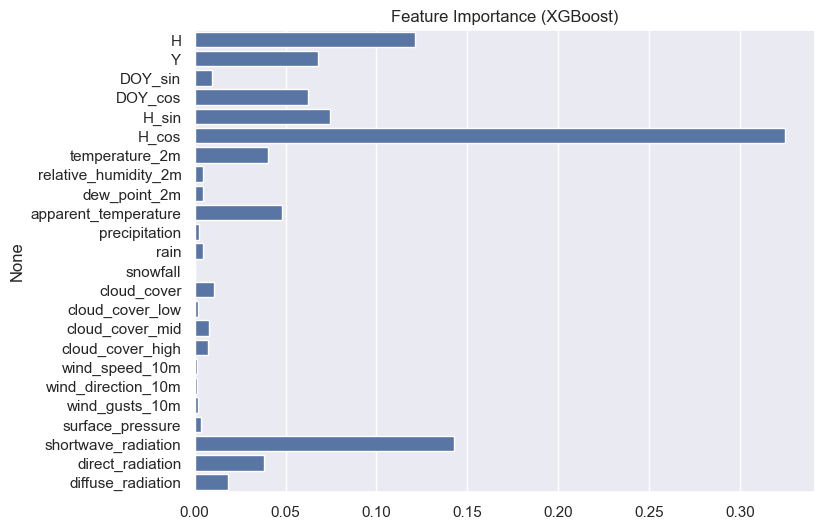

In [112]:
importances = xgb_search_model.feature_importances_
feat_names = Xses_train.columns

plt.figure(figsize=(8,6))
sns.barplot(x=importances, y=feat_names)
plt.title("Feature Importance (XGBoost)")
plt.savefig("Feature Importance (XGBoost).png", dpi=1000, bbox_inches="tight")

plt.show()




## RadnomSearch with Hist Gradient Boosting Regressor

In [113]:
hgb = HistGradientBoostingRegressor(random_state=42)

param_dist_hgb = {
    'max_depth': [2, 6, 8,12],
    'max_iter':[150,500,100],
    'learning_rate': [0.05, 0.1,0.15],
    'min_samples_leaf': [2, 4,7]
}

hgb_search_model = RandomizedSearchCV(
    estimator=hgb,
    param_distributions=param_dist_hgb,
    n_iter=30,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    random_state=42
)

hgb_search_model.fit(Xses_train_scaled, yses_train)
best_hgb_search_params = hgb_search_model.best_params_
print("Best HGB params:", best_hgb_search_params)


Best HGB params: {'min_samples_leaf': 4, 'max_iter': 500, 'max_depth': 12, 'learning_rate': 0.05}


In [114]:
hgb_search_model = HistGradientBoostingRegressor(
        random_state=42,
        **best_hgb_search_params
)
hgb_search_model.fit(Xses_train_scaled, yses_train)
y_pred_hgb_search = hgb_search_model.predict(Xses_test_scaled)
metrics_hgb_search = regression_metrics(yses_test, y_pred_hgb_search)

In [115]:
metrics_hgb_search

{'MAE': 27.391349204305012,
 'MSE': 2750.6720881736323,
 'RMSE': np.float64(52.44685012632915),
 'R2': 0.9448968828375452,
 'p_factor': np.float64(0.30432537120723047),
 'q_factor': np.float64(0.8223930664140323)}

## Metrics results

In [116]:

metrics_rf_random = regression_metrics(yses_test, y_pred_rfr)
metrics_xgb_search = regression_metrics(yses_test, y_pred_xgb_search)
metrics_hgb_search = regression_metrics(yses_test, y_pred_hgb_search)


In [117]:
import pandas as pd

rows = []

models_metrics = [
    ("RandomForest_RandomSearch",            metrics_rf_random),
    ("XGBoost_RandomSearch",               metrics_xgb_search),
    ("HistGradientBoosting_RandomSearch",  metrics_hgb_search),
]

for model_name, m in models_metrics:
    row = {"Model": model_name}
    row.update(m)
    rows.append(row)

metrics_table = pd.DataFrame(rows)
metrics_table

,Model,MAE,MSE,RMSE,R2,p_factor,q_factor
0,RandomForest_RandomSearch,25.874893,2501.693520,50.016932,0.949885,0.310523,0.832226
1,XGBoost_RandomSearch,26.823151,2464.523708,49.643970,0.950629,0.326275,0.826077
2,HistGradientBoosting_RandomSearch,27.391349,2750.672088,52.446850,0.944897,0.304325,0.822393


## Table of Metrics results

In [118]:
import pandas as pd
import numpy as np

# =========================================================
# 0) SAFELY GET FEATURE NAMES
# =========================================================
try:
    feature_names = list(Xses_train.columns)
except Exception:
    try:
        feature_names = list(Xses_train_scaled.columns)
    except Exception:
        feature_names = []

# =========================================================
# 1) DEFINE FEATURES USED PER MODEL
# =========================================================
features_by_model = {
    "RandomForest": feature_names,
    "XGBoost": feature_names,
    "HGB": feature_names,
}

aliases = {
    "RF": "RandomForest",
    "XGB": "XGBoost",
    "HGB": "HistGradientBoosting",
}

def get_features_for_model(model_name: str):
    model_key = aliases.get(model_name, model_name)
    feats = features_by_model.get(model_key, feature_names)
    return feats if isinstance(feats, (list, tuple)) else feature_names

# =========================================================
# 2) ADD FEATURE COLUMNS TO metrics_table
# =========================================================
metrics_table = metrics_table.copy()

metrics_table["Features_Used"] = metrics_table["Model"].apply(
    lambda m: ", ".join(get_features_for_model(m)) if len(get_features_for_model(m)) > 0 else "—"
)
metrics_table["n_features"] = metrics_table["Model"].apply(lambda m: len(get_features_for_model(m)))

# =========================================================
# 2.5) ENSURE MSE + Mean_Residual exist (robust)
# =========================================================

# If MSE missing but RMSE exists -> MSE = RMSE^2
if "MSE" not in metrics_table.columns and "RMSE" in metrics_table.columns:
    metrics_table["MSE"] = pd.to_numeric(metrics_table["RMSE"], errors="coerce") ** 2

# Normalize residual mean column name if it exists with a different label
resid_candidates = ["Mean_Residual", "mean_residual", "Residual_Mean", "residual_mean", "MeanResidual"]
found = next((c for c in resid_candidates if c in metrics_table.columns), None)
if found is not None and found != "Mean_Residual":
    metrics_table = metrics_table.rename(columns={found: "Mean_Residual"})

# =========================================================
# 3) SELECT COLUMNS FOR THE FINAL TABLE
# =========================================================
cols = [
    "Model",
    "n_features",
    "Features_Used",
    "MAE", "MSE", "RMSE",
    "R2",
    "Mean_Residual",
    "p_factor", "q_factor",
]

available_cols = [c for c in cols if c in metrics_table.columns]
mt = metrics_table[available_cols].copy()

# =========================================================
# 4) NUMERIC FORMATTING
# =========================================================
num_cols = ["n_features", "MAE", "MSE", "RMSE", "R2", "Mean_Residual", "p_factor", "q_factor"]
num_cols = [c for c in num_cols if c in mt.columns]

mt[num_cols] = mt[num_cols].apply(pd.to_numeric, errors="coerce").round(4)

# =========================================================
# 5) SORT BY MAIN METRIC
# =========================================================
if "R2" in mt.columns:
    mt = mt.sort_values("R2", ascending=False)

# =========================================================
# 6) STYLED TABLE
# =========================================================
format_dict = {
    "n_features": "{:.0f}",
    "MAE": "{:.3f}",
    "MSE": "{:.3f}",
    "RMSE": "{:.3f}",
    "R2": "{:.1%}",
    "Mean_Residual": "{:+.3f}",   # show sign
    "p_factor": "{:.1%}",
    "q_factor": "{:.1%}",
}
format_dict = {k: v for k, v in format_dict.items() if k in mt.columns}

styled = (
    mt.style
    .set_caption("Table X: Performance Metrics for Regression Models + Features")
    .format(format_dict)
)

high_max = [c for c in ["R2", "p_factor", "q_factor"] if c in mt.columns]
high_min = [c for c in ["MAE", "MSE", "RMSE"] if c in mt.columns]

# Mean_Residual best is closest to 0 (absolute min)
def highlight_abs_min(series):
    s = pd.to_numeric(series, errors="coerce")
    if s.notna().sum() == 0:
        return [""] * len(series)
    m = (s.abs()).min()
    return ["background-color: #fff2cc" if (np.isfinite(v) and abs(v) == m) else "" for v in s]

if high_max:
    styled = styled.highlight_max(subset=high_max, color="#b7e1cd")
if high_min:
    styled = styled.highlight_min(subset=high_min, color="#f4c7c3")
if "Mean_Residual" in mt.columns:
    styled = styled.apply(highlight_abs_min, subset=["Mean_Residual"])

# Gradient for R2 only (as you had)
if "R2" in mt.columns:
    styled = styled.background_gradient(subset=["R2"], cmap="Blues")

styled = styled.set_table_styles([
    {"selector": "caption",
     "props": [("font-size", "14px"),
               ("font-weight", "bold"),
               ("text-align", "left")]},
    {"selector": "th",
     "props": [("font-size", "12px"),
               ("font-weight", "bold"),
               ("border-bottom", "1px solid #000")]},
    {"selector": "td",
     "props": [("font-size", "11px"),
               ("padding", "4px 8px"),
               ("vertical-align", "top")]}
])

styled


,Model,n_features,Features_Used,MAE,MSE,RMSE,R2,p_factor,q_factor
1,XGBoost_RandomSearch,24,"H, Y, DOY_sin, DOY_cos, H_sin, H_cos, temperature_2m, relative_humidity_2m, dew_point_2m, apparent_temperature, precipitation, rain, snowfall, cloud_cover, cloud_cover_low, cloud_cover_mid, cloud_cover_high, wind_speed_10m, wind_direction_10m, wind_gusts_10m, surface_pressure, shortwave_radiation, direct_radiation, diffuse_radiation",26.823,2464.524,49.644,95.1%,32.6%,82.6%
0,RandomForest_RandomSearch,24,"H, Y, DOY_sin, DOY_cos, H_sin, H_cos, temperature_2m, relative_humidity_2m, dew_point_2m, apparent_temperature, precipitation, rain, snowfall, cloud_cover, cloud_cover_low, cloud_cover_mid, cloud_cover_high, wind_speed_10m, wind_direction_10m, wind_gusts_10m, surface_pressure, shortwave_radiation, direct_radiation, diffuse_radiation",25.875,2501.693,50.017,95.0%,31.1%,83.2%
2,HistGradientBoosting_RandomSearch,24,"H, Y, DOY_sin, DOY_cos, H_sin, H_cos, temperature_2m, relative_humidity_2m, dew_point_2m, apparent_temperature, precipitation, rain, snowfall, cloud_cover, cloud_cover_low, cloud_cover_mid, cloud_cover_high, wind_speed_10m, wind_direction_10m, wind_gusts_10m, surface_pressure, shortwave_radiation, direct_radiation, diffuse_radiation",27.391,2750.672,52.447,94.5%,30.4%,82.2%


## EDA Comparison of Prediction and Real Solar Panel Output

In [51]:
# List of all predictions
y_pred_algo = [

    y_pred_rfr,
    y_pred_xgb_search,
    y_pred_hgb_search,

]

# Matching names for legends/titles
algo_names = [

      "RandomForest_RandomSearch",
      "XGBoost_RandomSearch",
      "HistGradientBoosting_RandomSearch",
]


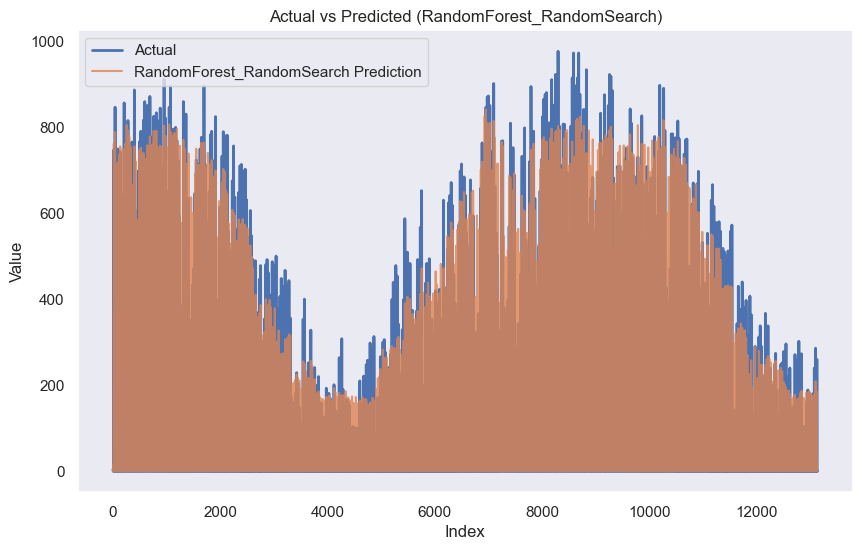

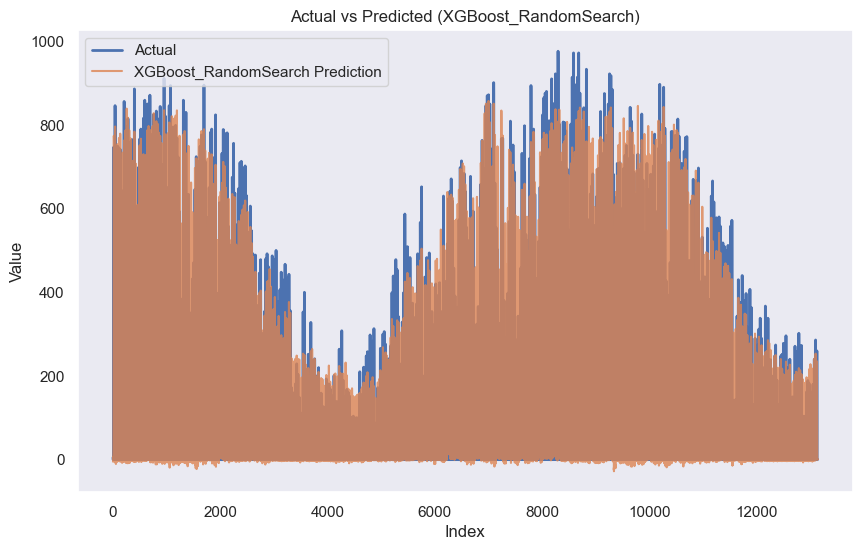

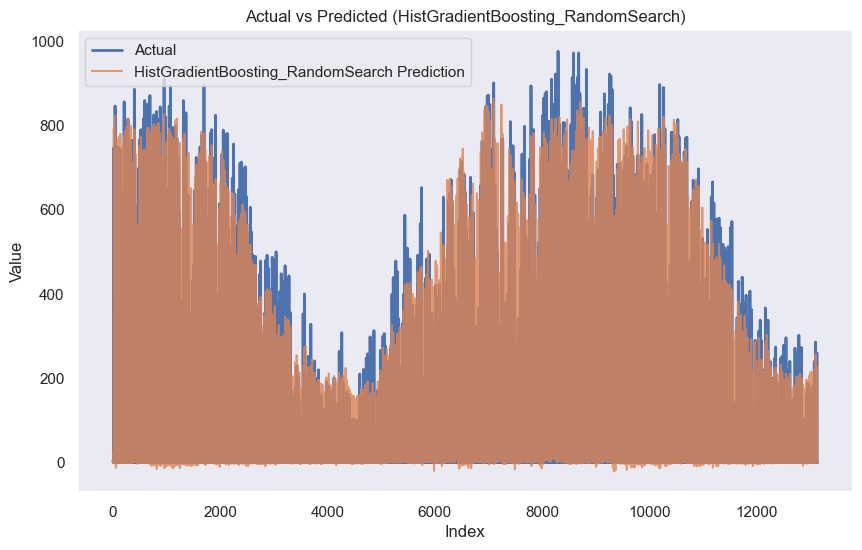

In [52]:
import os

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    plt.figure(figsize=(10,6))
    plt.plot(yses_test.values, label="Actual", linewidth=2)
    plt.plot(y_pred, label=f"{name} Prediction", alpha=0.8)
    plt.legend()
    plt.title(f"Actual vs Predicted ({name})")
    plt.xlabel("Index")   
    plt.ylabel("Value")
    plt.grid()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    plt.savefig(f"plots/actual_vs_pred_{safe_name}.png", dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close()  # avoid memory issues in loops


## EDA of Residuals on Histplot and Line

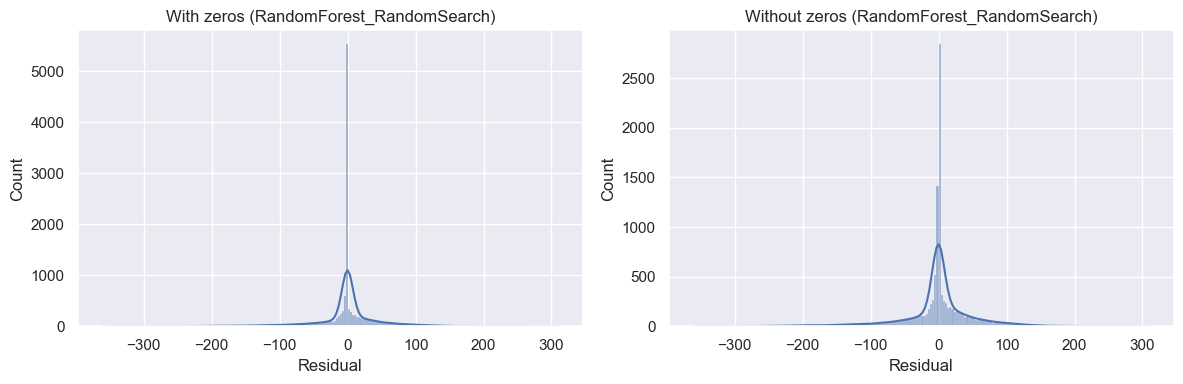

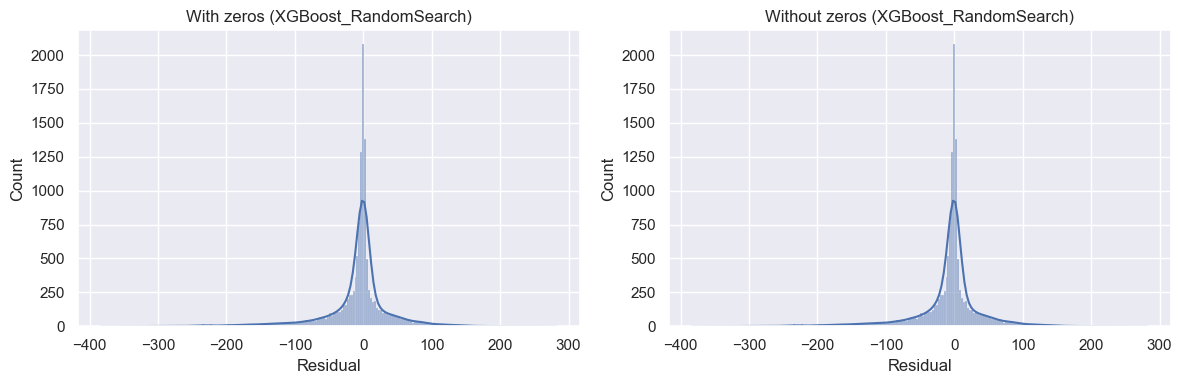

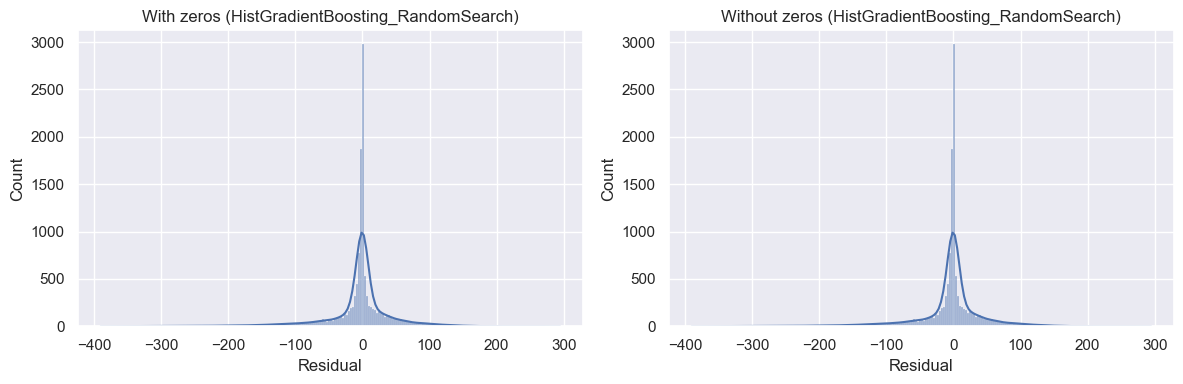

In [53]:
import os

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    residuals = yses_test.values - y_pred
    residuals_no0 = residuals[residuals != 0]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(residuals, kde=True, ax=ax[0])
    ax[0].set_title(f"With zeros ({name})")

    sns.histplot(residuals_no0, kde=True, ax=ax[1])
    ax[1].set_title(f"Without zeros ({name})")

    for a in ax:
        a.grid(True)
        a.set_xlabel("Residual")

    plt.tight_layout()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    fig.savefig(f"plots/residuals_with_vs_without_zeros_{safe_name}.png",
                dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close(fig)


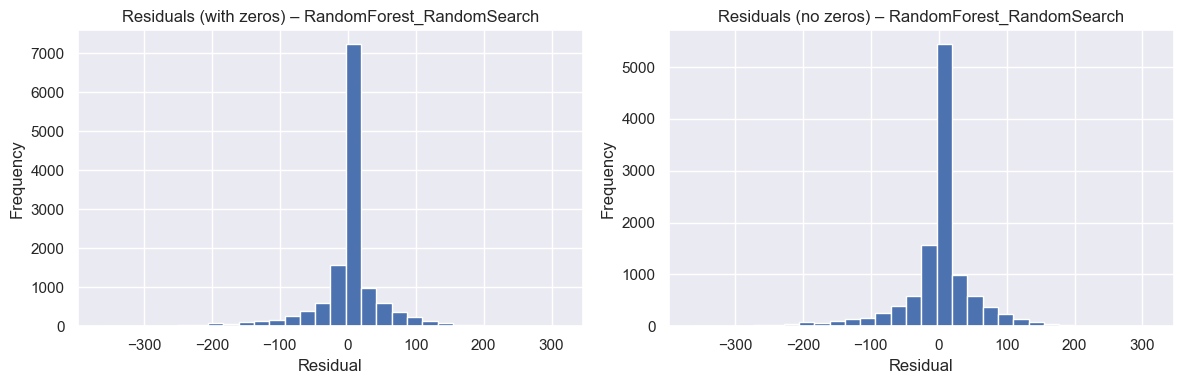

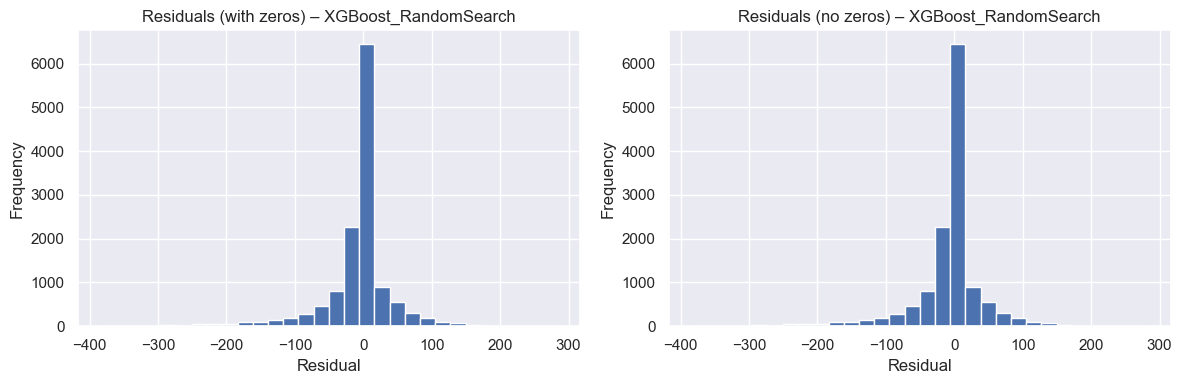

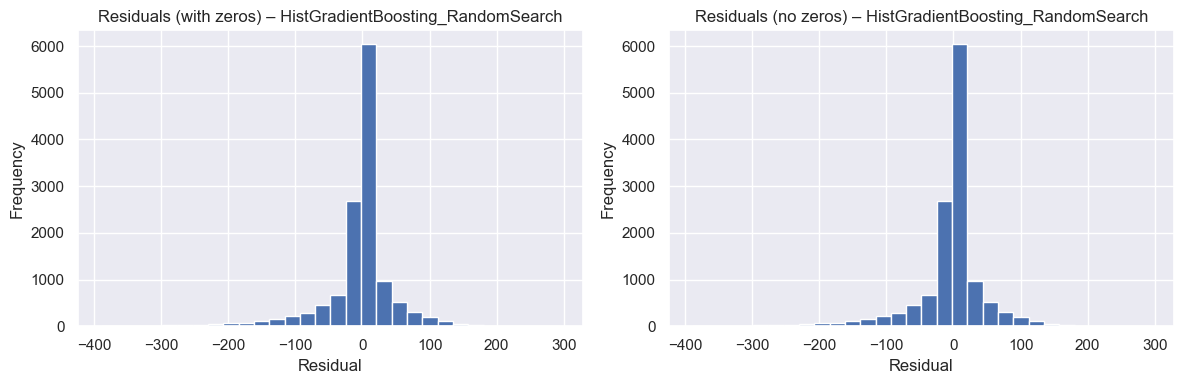

In [54]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    # residuals = Actual - Predicted
    res = yses_test.values - y_pred
    res_no0 = res[res != 0]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # With zeros
    ax[0].hist(res, bins=30)
    ax[0].set_title(f"Residuals (with zeros) – {name}")
    ax[0].set_xlabel("Residual")
    ax[0].set_ylabel("Frequency")
    ax[0].grid(True)

    # Without zeros
    ax[1].hist(res_no0, bins=30)
    ax[1].set_title(f"Residuals (no zeros) – {name}")
    ax[1].set_xlabel("Residual")
    ax[1].set_ylabel("Frequency")
    ax[1].grid(True)

    plt.tight_layout()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    fig.savefig(f"plots/residuals_with_vs_nozeros_{safe_name}.png",
                dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close(fig)


## EDA of Residuals Distribution comparison between Actual and Predicted

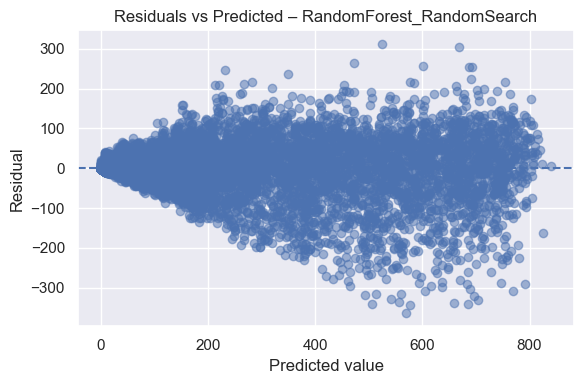

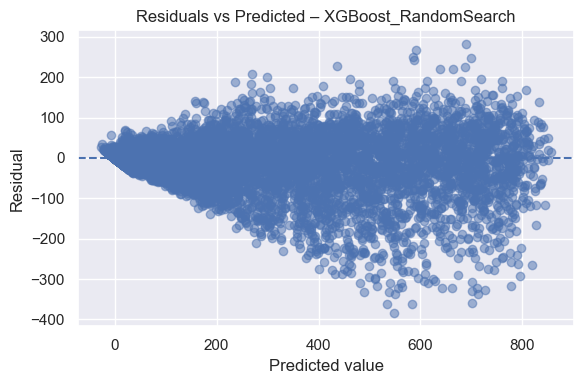

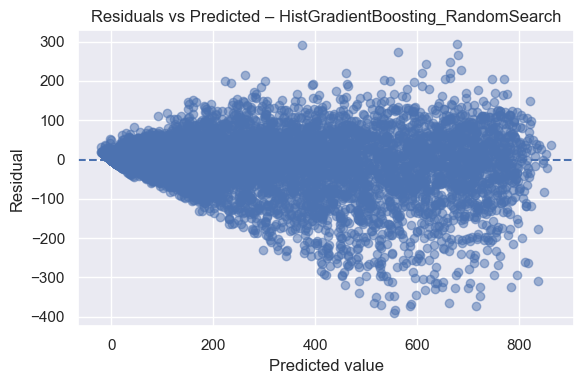

In [55]:
import os
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    # 1) Residuals
    residuals = yses_test.values - y_pred

    plt.figure(figsize=(6, 4))
    plt.scatter(y_pred, residuals, alpha=0.5)
    plt.axhline(0, linestyle="--")  # zero line
    plt.title(f"Residuals vs Predicted – {name}")
    plt.xlabel("Predicted value")
    plt.ylabel("Residual")
    plt.grid(True)
    plt.tight_layout()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    plt.savefig(f"plots/residuals_vs_pred_{safe_name}.png", dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close()


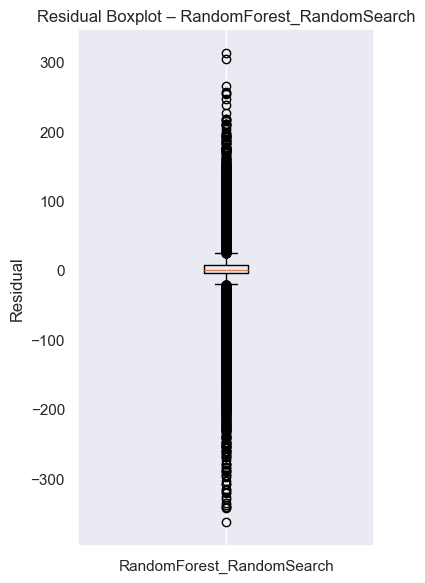

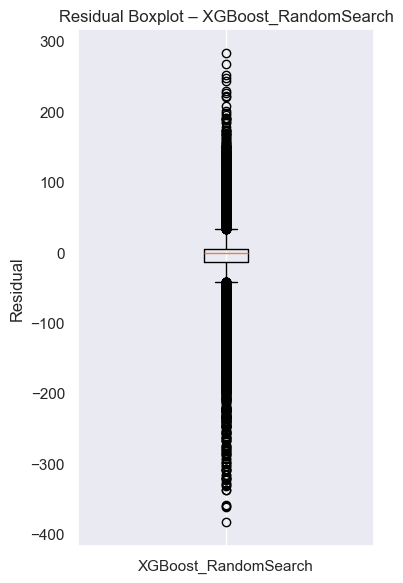

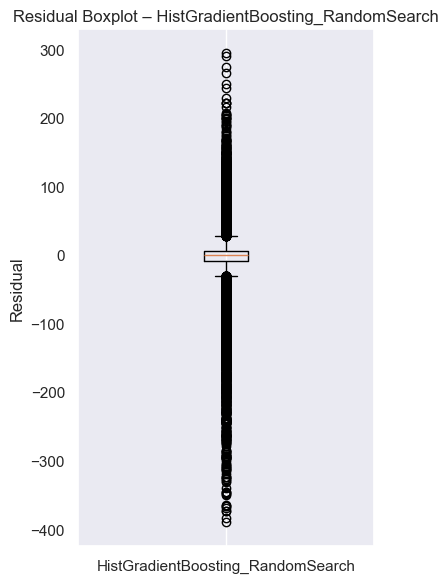

In [56]:
import os
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    residuals = yses_test.values - y_pred

    plt.figure(figsize=(4,6))
    plt.boxplot(residuals, vert=True)
    plt.title(f"Residual Boxplot – {name}")
    plt.ylabel("Residual")
    plt.xticks([1], [name])
    plt.grid(axis="y")
    plt.tight_layout()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    plt.savefig(f"plots/residual_boxplot_{safe_name}.png", dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close()


## EDA actual vs prediction 

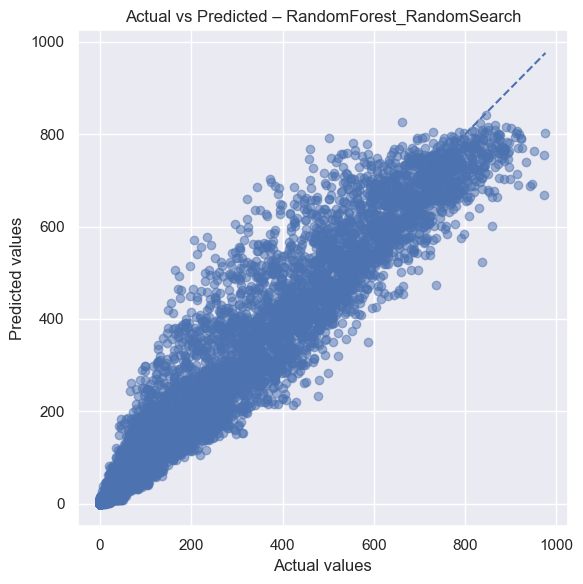

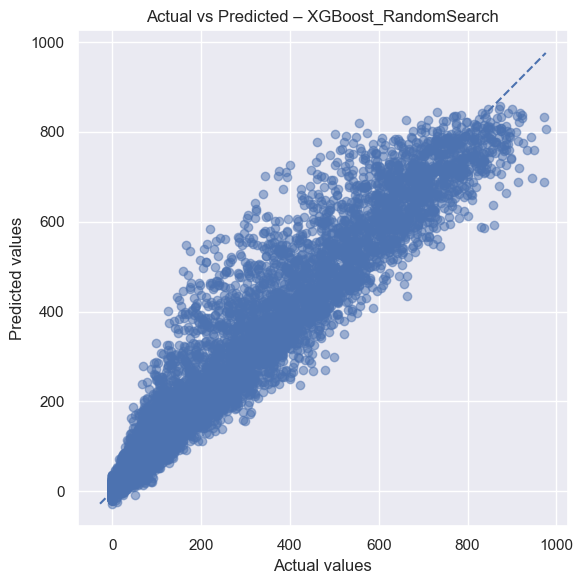

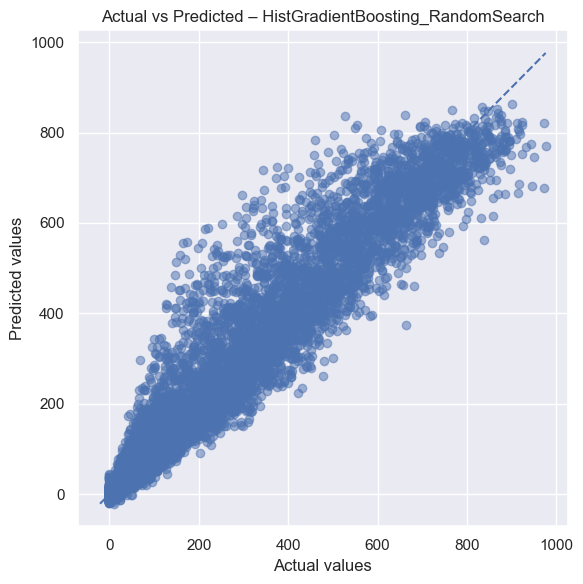

In [57]:
import os
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

for y_pred, name in zip(y_pred_algo, algo_names):
    plt.figure(figsize=(6,6))
    plt.scatter(yses_test.values, y_pred, alpha=0.5)
    plt.xlabel("Actual values")
    plt.ylabel("Predicted values")
    plt.title(f"Actual vs Predicted – {name}")
    plt.grid(True)

    min_val = min(yses_test.min(), y_pred.min())
    max_val = max(yses_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], '--')

    plt.tight_layout()

    safe_name = str(name).replace(" ", "_").replace("/", "_").replace("\\", "_")
    plt.savefig(f"plots/actual_vs_pred_scatter_{safe_name}.png", dpi=1000, bbox_inches="tight")

    plt.show()
    plt.close()


In [58]:
# Models for feature importance plots

models = {
    "RandomForest_RandomSearch":      best_rf_random,    
    "XGBoost_RandomSearch":   xgb_search_model,
    'HistGradiantBoost_RandomSearch': hgb_search_model,  

}



## SHAP explainer AI

In [59]:
#0️⃣ Imports & SHAP explainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor, plot_importance
from sklearn.metrics import mean_absolute_error, r2_score


from sklearn.inspection import PartialDependenceDisplay  #PDP shows: if I change one feature (e.g. radiation) and average everything else, how does the prediction change?
#global explainability helps you see the general relationship between a feature and the model output.


import shap  #It tells you how much each feature contributes to each prediction (local explanation) and globally what features matter most

shap.initjs()  # for interactive plots in notebooks

explainer = shap.TreeExplainer(xgb_search_model)  #creates a special explainer object 


<Figure size 800x600 with 0 Axes>

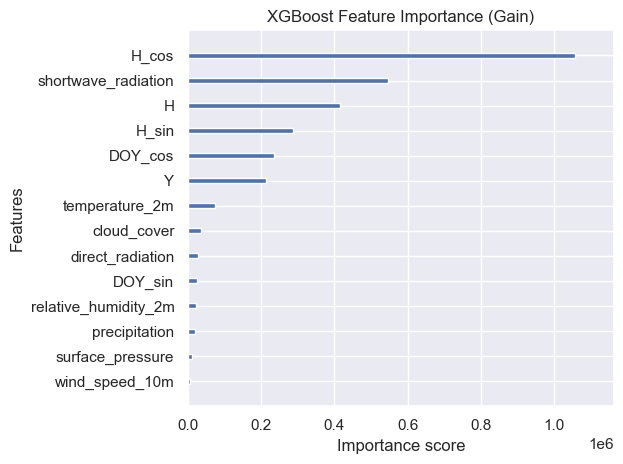

<Figure size 800x600 with 0 Axes>

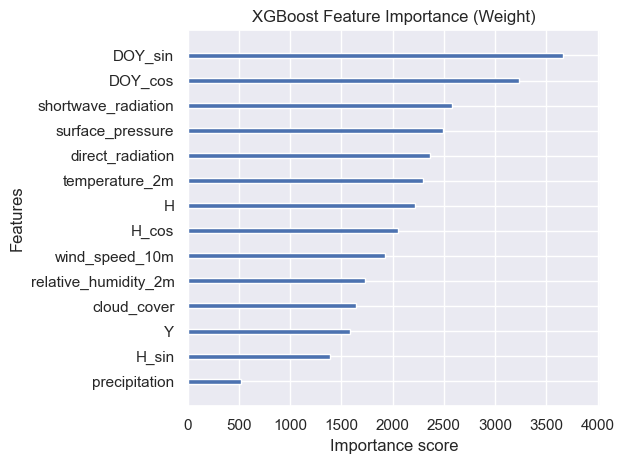

In [60]:
import os
import matplotlib.pyplot as plt
from xgboost import plot_importance

os.makedirs("plots", exist_ok=True)

# If xgb_search_model is a Grid/RandomizedSearchCV object,
# use best_estimator_. Otherwise, use it directly.
xgb_model = getattr(xgb_search_model, "best_estimator_", xgb_search_model)

# =========================
# Gain-based importance
# =========================
plt.figure(figsize=(8, 6))
plot_importance(
    xgb_model,
    importance_type="gain",
    show_values=False
)
plt.title("XGBoost Feature Importance (Gain)")
plt.tight_layout()

plt.savefig("plots/xgb_feature_importance_gain.png", dpi=1000, bbox_inches="tight")
plt.show()
plt.close()

# =========================
# Weight-based importance
# =========================
plt.figure(figsize=(8, 6))
plot_importance(
    xgb_model,
    importance_type="weight",
    show_values=False
)
plt.title("XGBoost Feature Importance (Weight)")
plt.tight_layout()

plt.savefig("plots/xgb_feature_importance_weight.png", dpi=1000, bbox_inches="tight")
plt.show()
plt.close()


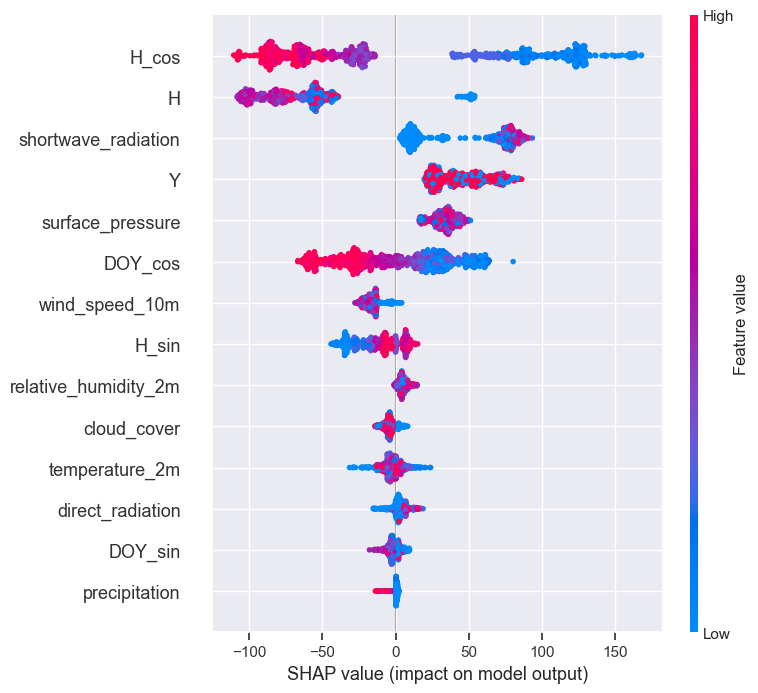

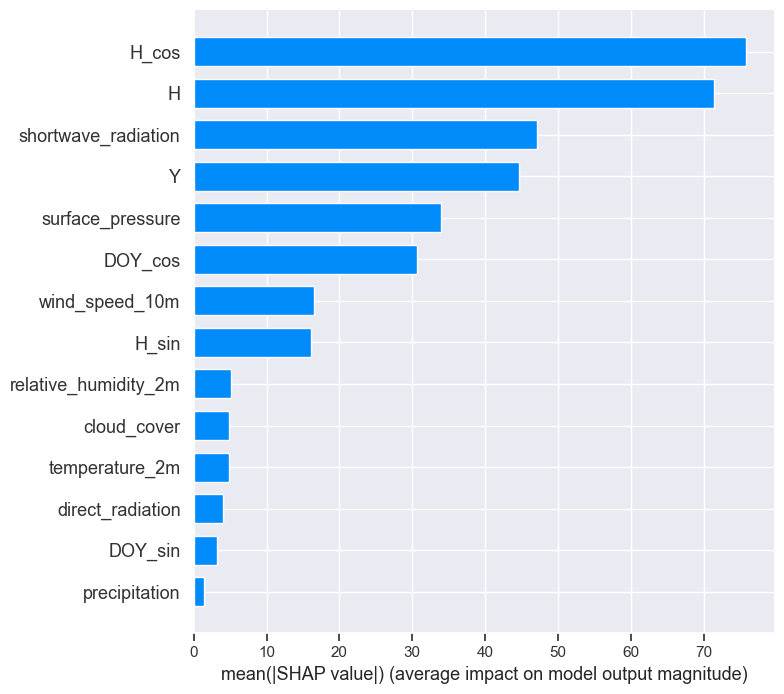

In [61]:
import os
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)

#2️⃣ GLOBAL – SHAP summary plots
# Use a sample of X_test if it's large (for speed)
X_sample = Xses_test.copy()
if X_sample.shape[0] > 1000:
    X_sample = X_sample.sample(1000, random_state=42)

# Compute SHAP values
shap_values = explainer.shap_values(X_sample)

# ===== Beeswarm summary (direction + magnitude) =====
plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_values,
    X_sample,
    show=False
)
plt.tight_layout()
plt.savefig("plots/shap_summary_beeswarm.png", dpi=1000, bbox_inches="tight")
plt.show()
plt.close()

# ===== Global bar plot (mean |SHAP| per feature) =====
plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar",
    show=False
)
plt.tight_layout()
plt.savefig("plots/shap_summary_bar.png", dpi=1000, bbox_inches="tight")
plt.show()
plt.close()


Available columns: ['H', 'Y', 'DOY_sin', 'DOY_cos', 'H_sin', 'H_cos', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m', 'surface_pressure', 'shortwave_radiation', 'direct_radiation']


C:\Users\DELL\anaconda3\envs\env\Lib\site-packages\sklearn\inspection\_partial_dependence.py:721: FutureWarning: The column 0 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
C:\Users\DELL\anaconda3\envs\env\Lib\site-packages\sklearn\inspection\_partial_dependence.py:721: FutureWarning: The column 1 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
C:\Users\DELL\anaconda3\envs\env\Lib\site-packages\sklearn\inspection\_plot\

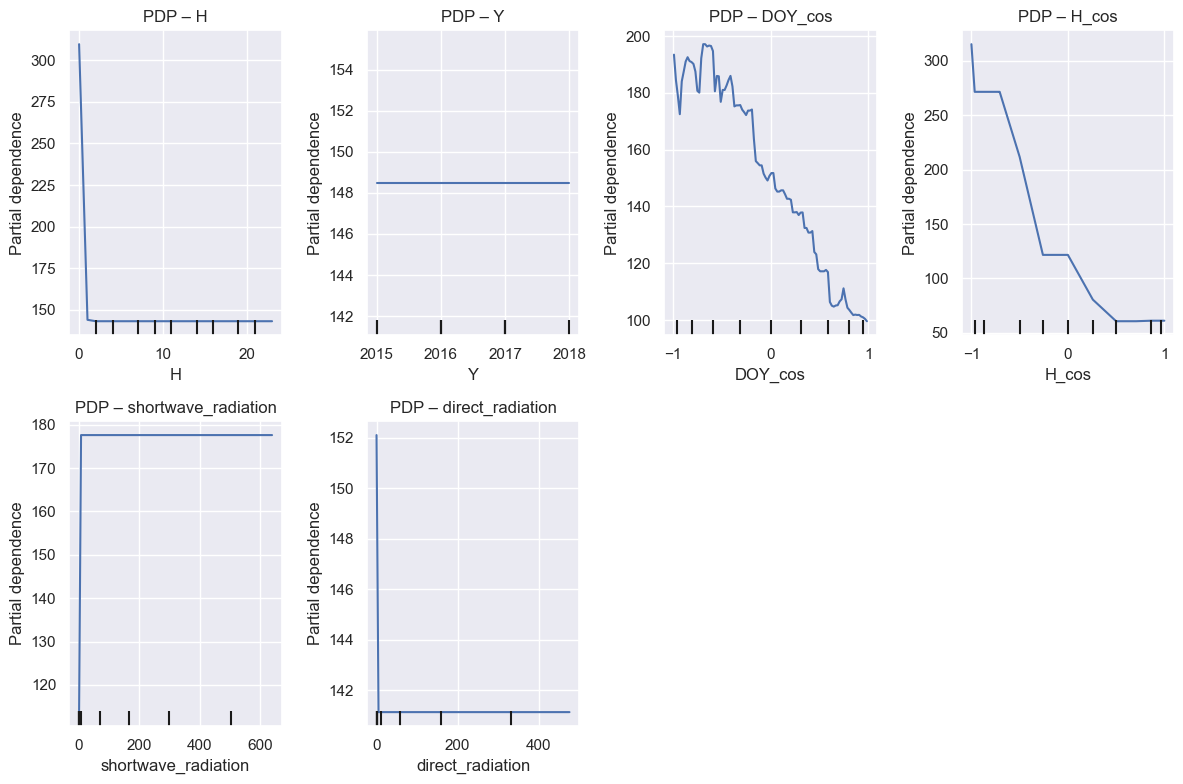

In [62]:
import os
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

os.makedirs("plots", exist_ok=True)

# If xgb_search_model is Grid/RandomizedSearchCV, use best_estimator_
xgb_model = getattr(xgb_search_model, "best_estimator_", xgb_search_model)

# 3️⃣ GLOBAL – Partial Dependence Plots (PDP)
pdp_features = ['H', 'Y', 'DOY_cos', 'H_cos', 'shortwave_radiation', 'direct_radiation']

print("Available columns:", Xses_train.columns.tolist())

fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(12, 8))

# Plot PDPs
for feature, axi in zip(pdp_features, ax.ravel()):
    PartialDependenceDisplay.from_estimator(
        xgb_model,
        Xses_train,
        [feature],
        ax=axi
    )
    axi.set_title(f"PDP – {feature}")
    axi.grid(True)

# Hide any leftover empty axes
for axi in ax.ravel()[len(pdp_features):]:
    axi.axis("off")

plt.tight_layout()

# ✅ Save the full PDP grid as one image
plt.savefig("plots/pdp_grid_xgb.png", dpi=1000, bbox_inches="tight")

plt.show()
plt.close(fig)


Index: 30677
True y: 196.0
Pred y: 93.90288


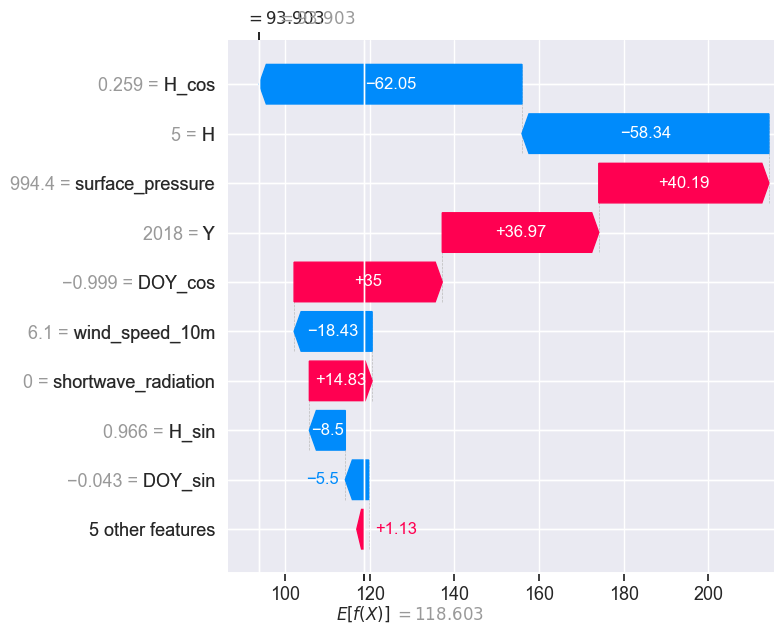

In [63]:
import os
import matplotlib.pyplot as plt
import shap

os.makedirs("plots", exist_ok=True)

# If xgb_search_model is Grid/RandomizedSearchCV, use best_estimator_
xgb_model = getattr(xgb_search_model, "best_estimator_", xgb_search_model)

# 4️⃣ LOCAL – SHAP for specific times / rows
i = 10
x_i = Xses_test.iloc[[i]]    # keep as DataFrame
y_true_i = yses_test.iloc[i]
y_pred_i = xgb_model.predict(x_i)[0]

print("Index:", Xses_test.index[i])
print("True y:", y_true_i)
print("Pred y:", y_pred_i)

shap_values_i = explainer.shap_values(x_i)

# Handle expected value safely (sometimes it's array-like)
expected_val = explainer.expected_value
if isinstance(expected_val, (list, np.ndarray)) and np.ndim(expected_val) > 0:
    expected_val = expected_val[0]

# Local waterfall explanation
exp_i = shap.Explanation(
    values=shap_values_i[0],
    base_values=expected_val,
    data=x_i.iloc[0],
    feature_names=x_i.columns
)

# ✅ Save waterfall
shap.plots.waterfall(exp_i, show=False)
safe_idx = str(Xses_test.index[i]).replace(" ", "_").replace(":", "_").replace("/", "_")
plt.tight_layout()
plt.savefig(f"plots/shap_waterfall_row_{i}_{safe_idx}.png", dpi=1000, bbox_inches="tight")
plt.show()
plt.close()


In [64]:


#5️⃣ LOCAL – Under/overestimation analysis with SHAP
# Predictions on test set
y_pred_test = xgb_search_model.predict(Xses_test)

# Residuals
residuals = yses_test - y_pred_test
abs_residuals = np.abs(residuals)

errors_df = pd.DataFrame({
    "y_true": yses_test,
    "y_pred": y_pred_test,
    "residual": residuals,
    "abs_residual": abs_residuals
}, index=Xses_test.index)

# Top N worst errors (largest absolute residuals)
N = 10000
worst_errors = errors_df.sort_values("abs_residual", ascending=False).head(N)
print(worst_errors)


       y_true      y_pred    residual  abs_residual
39251   972.0  375.440369  596.559631    596.559631
38963   976.0  397.990143  578.009857    578.009857
38962   924.0  361.179321  562.820679    562.820679
39491   933.0  372.106720  560.893280    560.893280
39347   972.0  424.098846  547.901154    547.901154
...       ...         ...         ...           ...
38057   113.0  137.752991  -24.752991     24.752991
42235     0.0   24.709066  -24.709066     24.709066
35649   156.0  180.696609  -24.696609     24.696609
36630    72.0   96.693024  -24.693024     24.693024
31863   351.0  375.683838  -24.683838     24.683838

[10000 rows x 4 columns]


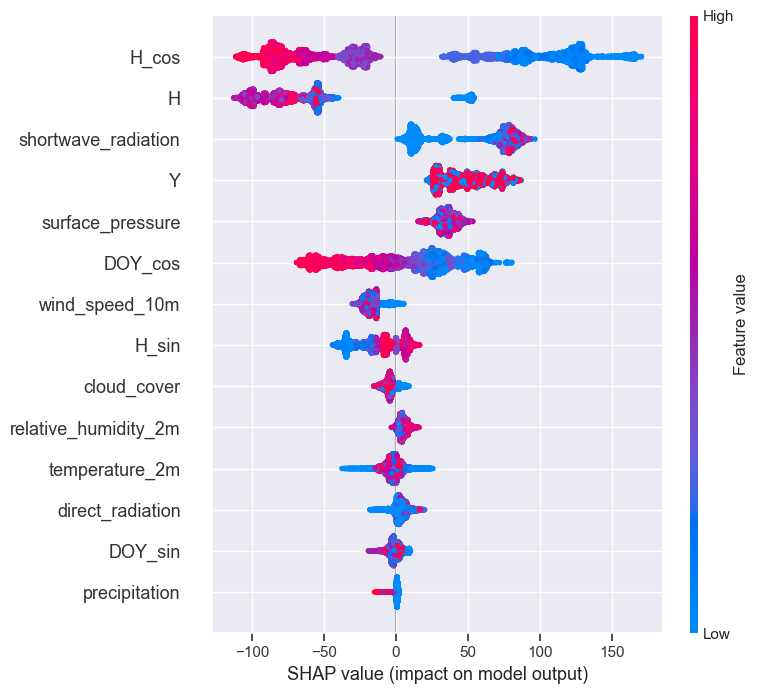

In [65]:

#5.2 SHAP for the worst N cases (group view)
# Take their feature rows
X_worst = Xses_test.loc[worst_errors.index]

# SHAP for these rows
shap_values_worst = explainer.shap_values(X_worst)

# SHAP summary ONLY for worst errors
shap.summary_plot(
    shap_values_worst,
    X_worst,
    show=True
)



Worst index: 39251
True y: 972.0
Pred y: 375.44037
Residual (y_true - y_pred): 596.5596313476562


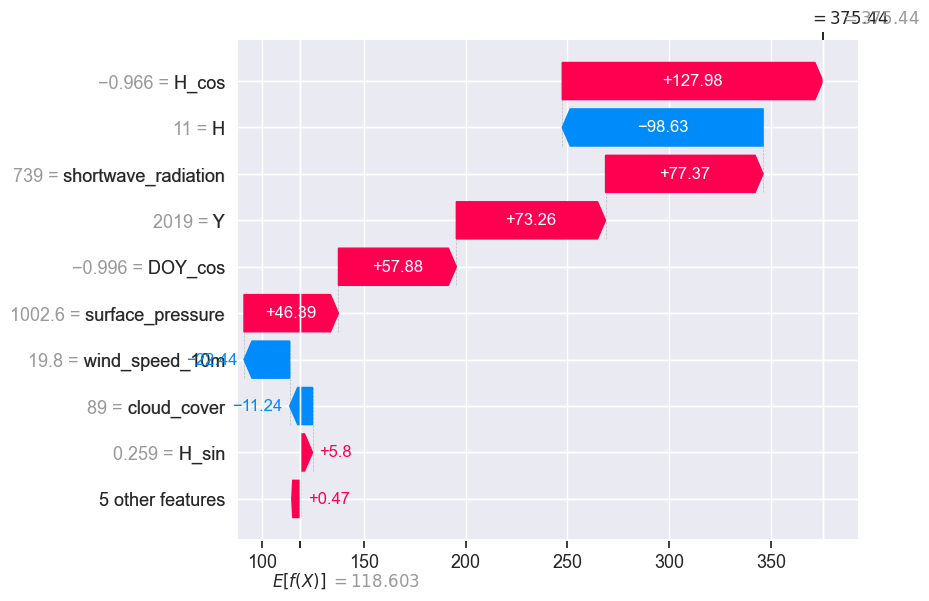

In [66]:
#5.3 Detailed SHAP for the single worst case
# Single worst case (first row in worst_errors)
worst_idx = worst_errors.index[0]

x_worst = Xses_test.loc[[worst_idx]]
y_true_worst = yses_test.loc[worst_idx]
y_pred_worst = xgb_search_model.predict(x_worst)[0]

print("Worst index:", worst_idx)
print("True y:", y_true_worst)
print("Pred y:", y_pred_worst)
print("Residual (y_true - y_pred):", y_true_worst - y_pred_worst)

shap_values_worst_single = explainer.shap_values(x_worst)

exp_worst = shap.Explanation(
    values=shap_values_worst_single[0],
    base_values=explainer.expected_value,
    data=x_worst.iloc[0],
    feature_names=x_worst.columns
)
shap.plots.waterfall(exp_worst)


In [67]:
import joblib

models = {
    "rf_reg_model":  rf_random_model,
    "xgb_search_model": xgb_search_model,
    "hgb_search_model": hgb_search_model,
}

joblib.dump(models, "all_models.pkl")
print("Saved all models in all_models.pkl")

Saved all models in all_models.pkl


In [68]:
models = joblib.load("all_models.pkl")   # returns the same dict

xgb_loaded = models["xgb_search_model"]
hgb_loaded = models["hgb_search_model"]
